
Best Task Allocation:
Processor 1: [2, 4, 8]
Processor 2: [1, 3, 5]
Processor 3: [6, 7, 9, 10]

Processor Workloads: [19. 17. 19.]
Minimum Makespan: 19.0


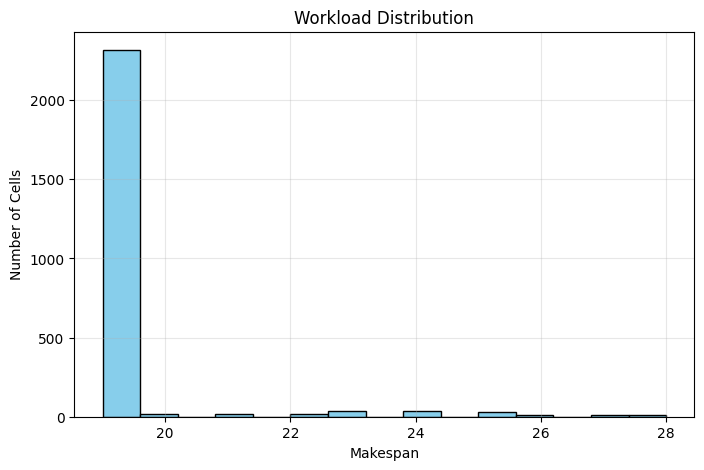

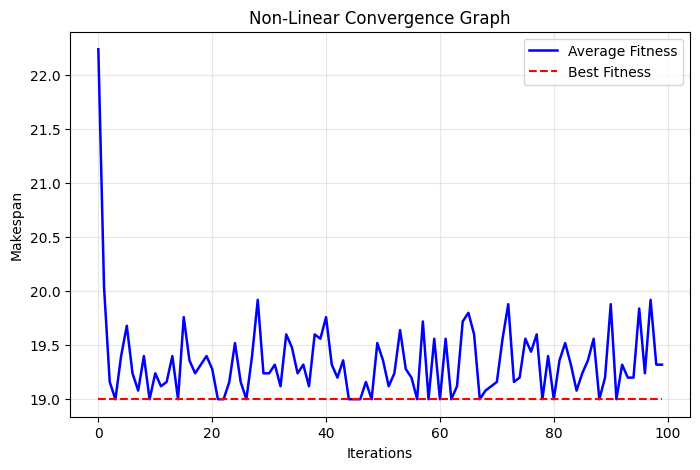

In [1]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)


tasks = [8, 6, 5, 7, 4, 9, 3, 6, 2, 5]
processors = 3
grid_size = 5
iterations = 100
mutation_rate = 0.1


grid = np.random.randint(
    0, processors,
    (grid_size, grid_size, len(tasks))
)

convergence = []
best_convergence = []
workload = []


def fitness(solution):
    loads = np.zeros(processors)

    for i, p in enumerate(solution):
        loads[p] += tasks[i]

    return max(loads)


def neighbors(i, j):
    return [
        ((i - 1) % grid_size, j),
        ((i + 1) % grid_size, j),
        (i, (j - 1) % grid_size),
        (i, (j + 1) % grid_size)
    ]


global_best = None
global_best_fitness = float('inf')

for iteration in range(iterations):

    new_grid = grid.copy()

    for i in range(grid_size):
        for j in range(grid_size):

            current = grid[i, j].copy()
            best = current.copy()


            for ni, nj in neighbors(i, j):

                candidate = grid[ni, nj]

                if fitness(candidate) < fitness(best):
                    best = candidate.copy()


            if np.random.rand() < mutation_rate:

                k = np.random.randint(len(tasks))
                best[k] = np.random.randint(processors)

            new_grid[i, j] = best

    grid = new_grid


    scores = [
        fitness(grid[i, j])
        for i in range(grid_size)
        for j in range(grid_size)
    ]


    avg_fitness = np.mean(scores)


    current_best = min(scores)


    convergence.append(avg_fitness)
    best_convergence.append(current_best)

    workload.extend(scores)


    best_index = np.argmin(scores)
    best_solution = grid.reshape(-1, len(tasks))[best_index].copy()

    if current_best < global_best_fitness:
        global_best_fitness = current_best
        global_best = best_solution.copy()



loads = np.zeros(processors)

for i, p in enumerate(global_best):
    loads[p] += tasks[i]



print("\nBest Task Allocation:")

for p in range(processors):
    assigned_tasks = [
        i + 1
        for i in range(len(tasks))
        if global_best[i] == p
    ]

    print(f"Processor {p + 1}: {assigned_tasks}")

print("\nProcessor Workloads:", loads)
print("Minimum Makespan:", max(loads))



plt.figure(figsize=(8, 5))

plt.hist(
    workload,
    bins=15,
    edgecolor='black',
    color='skyblue'
)

plt.xlabel("Makespan")
plt.ylabel("Number of Cells")
plt.title("Workload Distribution")
plt.grid(alpha=0.3)

plt.show()



plt.figure(figsize=(8, 5))

plt.plot(
    convergence,
    color='blue',
    linewidth=1.8,
    label='Average Fitness'
)

plt.plot(
    best_convergence,
    color='red',
    linewidth=1.5,
    linestyle='--',
    label='Best Fitness'
)

plt.xlabel("Iterations")
plt.ylabel("Makespan")
plt.title("Non-Linear Convergence Graph")

plt.legend()
plt.grid(alpha=0.3)

plt.show()
